# MDP e Equação de Bellman — a grade 4×3 da aula

Este notebook acompanha os slides **48 a 69** e o "mão na massa" do **slide 66**.

**A pergunta do notebook:** um robô começa no START. Ele quer chegar ao diamante 💎 (+1) sem cair no fogo 🔥 (−1). **Quanto vale cada casa da grade**, e qual é a **melhor seta** a seguir em cada uma?

A grade é exatamente a da aula:

```
 ┌───────┬───────┬───────┬───────┐
 │       │       │       │  +1 💎 │   linha 0
 ├───────┼───────┼───────┼───────┤
 │       │ ████  │       │  −1 🔥 │   linha 1
 ├───────┼───────┼───────┼───────┤
 │ START │       │       │       │   linha 2
 └───────┴───────┴───────┴───────┘
  coluna 0  coluna 1 coluna 2 coluna 3
```

**Como ler as coordenadas:** no código, cada casa é `(linha, coluna)`, com a **linha 0 no topo**. Exemplos: o START é `(2, 0)`, o diamante é `(0, 3)`, o fogo é `(1, 3)` e a parede ████ é `(1, 1)`.

### Os cinco ingredientes do MDP (slide 51)

| Ingrediente | Símbolo | Em palavras | Nesta grade |
|---|---|---|---|
| **Estados** | S | "Onde estou?" | As 11 casas livres (a parede não é estado) |
| **Ações** | A | "O que posso fazer?" | ↑ ↓ ← → |
| **Transição** | P(s'\|s,a) | "Se eu fizer *a*, aonde vou parar?" | Determinística, ou ruidosa: 80% para onde pediu, 10% para cada lado (slide 50) |
| **Recompensa** | R(s,a) | "Quanto ganho neste passo?" | +1 ao entrar no diamante, −1 ao entrar no fogo, 0 nos demais passos (slide 58) |
| **Desconto** | γ | "Quanto vale o futuro?" | 0,9: cada passo a mais multiplica o prêmio por 0,9 (slide 61) |

### Roteiro do "mão na massa" (slide 66)

| Item do slide 66 | Onde está neste notebook |
|---|---|
| 1. Rodar a grade 4×3 do exemplo | Seções 2 a 5 |
| 2. Calcular V(s) com γ = 0,9 e comparar com a aula: 1 · 0,9 · 0,81 · 0,73 · 0,66 | Seção 6 |
| 3. Trocar γ para 0,5 e 0,99: o que acontece com o valor do START? | Seção 8 |
| 4. Mudar o fogo para −10: a política muda? | Seção 10 |

**Como usar:** execute as células **em ordem**, de cima para baixo (Shift + Enter). Antes de cada resultado importante há uma pergunta: **aposte numa resposta antes de rodar**.

> **Dica:** façam em duplas — um digita, o outro prevê o resultado antes de rodar.

---
## 1. Importações

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

---
## 2. O ambiente

As células abaixo montam a grade em código. Vale guardar três regras:

- **Terminais:** o diamante e o fogo são **estados terminais**. Ao entrar num deles o agente recebe a recompensa e o episódio acaba.
- **Parede e borda:** se a ação leva para a parede ou para fora da grade, o agente **fica parado** na mesma casa (e gasta um passo).
- **A função `plot_grade`:** desenha a grade. Em cada casa aparecem o **valor V(s)** (o número) e a **ação escolhida** (a seta). A cor vai do vermelho (valor baixo) ao verde (valor alto).

Ao rodar, confira a contagem: **11 estados = 9 casas onde o agente decide + 2 terminais**.

In [2]:
# ======================================================================
# 📚 NA AULA · MDP: o mundo da grade 4×3
#   Ingrediente S (estados): as casas, a parede, o START e os terminais (diamante e fogo).
# ======================================================================
LINHAS, COLUNAS = 3, 4

PAREDE   = (1, 1)
DIAMANTE = (0, 3)   # +1 e fim do episódio
FOGO     = (1, 3)   # −1 e fim do episódio
START    = (2, 0)
TERMINAIS = [DIAMANTE, FOGO]

ACOES = ['cima', 'direita', 'baixo', 'esquerda']
DELTA = {'cima': (-1, 0), 'baixo': (1, 0), 'esquerda': (0, -1), 'direita': (0, 1)}
LADOS = {'cima': ('esquerda', 'direita'), 'baixo': ('esquerda', 'direita'),
         'esquerda': ('cima', 'baixo'), 'direita': ('cima', 'baixo')}
SETAS = {'cima': '↑', 'baixo': '↓', 'esquerda': '←', 'direita': '→'}

# Todos os estados: células da grade, menos a parede
ESTADOS = [(r, c) for r in range(LINHAS) for c in range(COLUNAS) if (r, c) != PAREDE]

print(f'Grade {COLUNAS}×{LINHAS} | {len(ESTADOS)} estados '
      f'({len(ESTADOS) - len(TERMINAIS)} não terminais + {len(TERMINAIS)} terminais)')

Grade 4×3 | 11 estados (9 não terminais + 2 terminais)


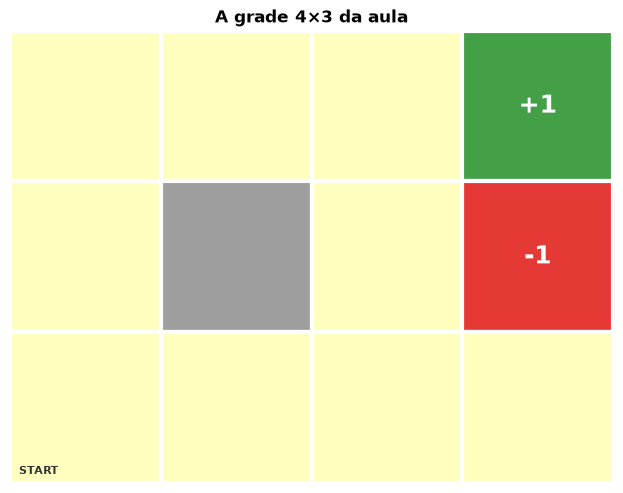

In [3]:
def plot_grade(V=None, politica=None, titulo='', ax=None, r_fogo=-1.0, destaque=()):
    '''Desenha a grade com V(s) em cada célula e a seta da política.
    `destaque` recebe células para contornar em laranja.'''
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(6.5, 5))
    norma = Normalize(vmin=-1, vmax=1)
    for r in range(LINHAS):
        for c in range(COLUNAS):
            s, x, y = (r, c), c, LINHAS - 1 - r
            if s == PAREDE:
                cor, texto = '#9E9E9E', ''
            elif s == DIAMANTE:
                cor, texto = '#43A047', '+1'
            elif s == FOGO:
                cor, texto = '#E53935', f'{r_fogo:+g}'.replace('.', ',')
            else:
                v = 0.0 if V is None else V[s]
                cor = plt.cm.RdYlGn(norma(np.clip(v, -1, 1)) * 0.7 + 0.15)
                texto = '' if V is None else f'{v:.2f}'
            ax.add_patch(plt.Rectangle((x, y), 1, 1, facecolor=cor, edgecolor='white', linewidth=3))
            if s in TERMINAIS:
                ax.text(x + 0.5, y + 0.5, texto, ha='center', va='center',
                        fontsize=18, fontweight='bold', color='white')
            elif s != PAREDE:
                ax.text(x + 0.5, y + 0.38, texto, ha='center', va='center', fontsize=12, fontweight='bold')
                if politica:
                    ax.text(x + 0.5, y + 0.7, SETAS[politica[s]], ha='center', va='center', fontsize=20)
            if s == START:
                ax.text(x + 0.06, y + 0.06, 'START', fontsize=8, fontweight='bold', color='#333')
            if s in destaque:
                ax.add_patch(plt.Rectangle((x + 0.04, y + 0.04), 0.92, 0.92, fill=False,
                                           edgecolor='#FF6F00', linewidth=3.5))
    ax.set_xlim(0, COLUNAS)
    ax.set_ylim(0, LINHAS)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    if criou:
        plt.tight_layout()
        plt.show()


plot_grade(titulo='A grade 4×3 da aula')

---
## 3. Transições: determinística × ruidosa (slides 50 e 51)

Como dirigir em pista molhada: você pede **Norte**, mas o carro pode escorregar para o lado.

| Movimento | Determinístico | Ruidoso (ruído = 0,2) |
|---|---|---|
| Para onde pediu | 100% | 80% |
| Para cada lado | 0% | 10% |

"Para o lado" significa **perpendicular** à ação: quem pede ↑ pode escorregar para ← ou →. Se o movimento bate na parede ou na borda, o agente fica parado.

**Como ler a saída da célula abaixo:** a função `transicoes` devolve uma lista de pares `(probabilidade, próxima casa)`. Esse é o $P(s'|s,a)$ escrito em código. No exemplo, o agente está em `(2, 2)` e pede ↑:

- **Determinístico:** `[(1.0, (1, 2))]` — com certeza sobe para `(1, 2)`.
- **Ruidoso:** 80% sobe para `(1, 2)`, 10% escorrega para `(2, 1)` e 10% para `(2, 3)`. As probabilidades sempre somam 1.

In [4]:
# ======================================================================
# 📚 NA AULA · MDP: ingrediente P (probabilidade de transição)
#   Para onde cada ação leva: determinística ou ruidosa (80% / 10% / 10%).
# ======================================================================
def mover(s, a):
    '''Próxima célula ao executar a ação `a` em `s` (fica parado se bater).'''
    r, c = s[0] + DELTA[a][0], s[1] + DELTA[a][1]
    if not (0 <= r < LINHAS and 0 <= c < COLUNAS) or (r, c) == PAREDE:
        return s
    return (r, c)


def transicoes(s, a, ruido=0.0):
    '''P(s'|s,a) como lista de (probabilidade, próximo estado).'''
    if ruido == 0:
        return [(1.0, mover(s, a))]
    lado1, lado2 = LADOS[a]
    return [(1 - ruido, mover(s, a)),
            (ruido / 2, mover(s, lado1)),
            (ruido / 2, mover(s, lado2))]


s = (2, 2)   # a casa logo abaixo do 'corredor' do fogo
print(f"Estado {s}, ação 'cima':")
print('  determinístico:', transicoes(s, 'cima'))
print('  ruidoso       :', transicoes(s, 'cima', ruido=0.2))

Estado (2, 2), ação 'cima':
  determinístico: [(1.0, (1, 2))]
  ruidoso       : [(0.8, (1, 2)), (0.1, (2, 1)), (0.1, (2, 3))]


---
## 4. Recompensa e Equação de Bellman (slides 58 e 59)

$$V(s) = \max_a \sum_{s'} P(s'|s,a)\,\big[\,R(s,a,s') + \gamma \cdot V(s')\,\big]$$

**Em palavras:** o valor de uma casa é o que se ganha escolhendo a melhor ação. Esse ganho é **o prêmio deste passo** mais **o valor da casa seguinte, com desconto**. Quando a transição é ruidosa, faz-se a média ponderada pelas chances de cada destino.

| Peça | Significado | No código |
|---|---|---|
| $R(s,a,s')$ | O que ganho **agora**: +1 no diamante, −1 no fogo, 0 no resto | `recompensa` |
| $\gamma \cdot V(s')$ | O que vale o **futuro**: o valor de onde vou chegar, com desconto | dentro de `valor_acao` |
| $\sum_{s'} P(s'\|s,a)$ | A média sobre os lugares onde posso cair | o laço em `valor_acao` |
| $\max_a$ | Escolha a **melhor ação** | `melhor_acao` |

Depois de entrar num estado terminal o jogo acaba: o futuro vale **zero**.

**Exemplo (slide 62):** a célula abaixo calcula o valor de cada ação na casa `(0, 2)`, ao lado do diamante, com todos os V ainda zerados.

- **→ direita:** entra no diamante. $V = 1 + 0{,}9 \times 0 = 1$.
- **Qualquer outra ação:** cai numa casa comum, que ainda vale 0. Então $V = 0 + 0{,}9 \times 0 = 0$.

O $\max$ escolhe → e a casa passa a valer 1. **O valor nasce no objetivo.**

In [5]:
# ======================================================================
# 📚 NA AULA · MDP: ingrediente R (recompensa)
#   +1 no diamante, r_fogo no fogo e r_passo (living penalty) no resto.
# ======================================================================
def recompensa(s_prox, r_fogo=-1.0, r_passo=0.0):
    '''Recompensa recebida ao ENTRAR em s_prox. r_passo é a living penalty (slide 68).'''
    if s_prox == DIAMANTE:
        return 1.0
    if s_prox == FOGO:
        return r_fogo
    return r_passo


# ======================================================================
# 📚 NA AULA · EQUAÇÃO DE BELLMAN: valor de UMA ação
#   Q(s, a) = Σ P(s'|s,a) · [ R + γ · V(s') ]
# ======================================================================
def valor_acao(s, a, V, gamma=0.9, ruido=0.0, r_fogo=-1.0, r_passo=0.0):
    '''Σ P(s'|s,a) · [R + γ·V(s')]  — o termo dentro do max da equação de Bellman.'''
    total = 0.0
    for p, s_prox in transicoes(s, a, ruido):
        futuro = 0.0 if s_prox in TERMINAIS else V[s_prox]   # terminal: o jogo acaba
        total += p * (recompensa(s_prox, r_fogo, r_passo) + gamma * futuro)
    return total


# ======================================================================
# 📚 NA AULA · EQUAÇÃO DE BELLMAN (otimalidade): V(s) = max_a Q(s, a)
#   A melhor ação (argmax) é a política π(s).
# ======================================================================
def melhor_acao(s, V, gamma=0.9, ruido=0.0, r_fogo=-1.0, r_passo=0.0):
    '''max_a: devolve (melhor ação, valor). Em caso de empate, vale a ordem de ACOES.'''
    valores = [valor_acao(s, a, V, gamma, ruido, r_fogo, r_passo) for a in ACOES]
    i = int(np.argmax(np.round(valores, 10)))
    return ACOES[i], valores[i]


# Passo 1 do slide 62: a casa ao lado do diamante, com V ainda zerado
V0 = {s: 0.0 for s in ESTADOS}
s = (0, 2)
print(f'Casa ao lado do diamante {s}, com V = 0 em tudo:')
for a in ACOES:
    print(f'  {SETAS[a]} {a:9s} → {valor_acao(s, a, V0):.2f}')
print('\n→ indo para a direita: V = R + γ·V(s\') = 1 + 0,9 × 0 = 1   (o valor nasce no objetivo)')

Casa ao lado do diamante (0, 2), com V = 0 em tudo:
  ↑ cima      → 0.00
  → direita   → 1.00
  ↓ baixo     → 0.00
  ← esquerda  → 0.00

→ indo para a direita: V = R + γ·V(s') = 1 + 0,9 × 0 = 1   (o valor nasce no objetivo)


---
## 5. Value Iteration passo a passo (slides 62–64 e 77)

**A receita:**

1. Comece com V(s) = 0 em todos os estados.
2. **Varredura:** aplique a equação de Bellman em cada estado, usando os valores da varredura anterior.
3. Repita até a mudança (o **delta**) ficar menor que um limite θ.
4. Extraia π*: em cada estado, a ação de maior valor.

**Experimente:** execute a **segunda** célula abaixo **várias vezes**. Cada execução é uma varredura, e o valor nasce no diamante e se espalha para trás, multiplicado por 0,9 a cada casa:

| Iteração | O que aparece |
|---|---|
| 1 | Só `(0, 2)`, vizinha do diamante, vale **1** |
| 2 | As vizinhas dela, `(0, 1)` e `(1, 2)`, valem **0,9** |
| 3 | Mais uma casa para trás: **0,81** |
| 4–5 | 0,73 e 0,66 — o valor chega ao START |
| 6 | Nada muda: delta = 0, **convergiu** |

> ⚠️ **Setas em casas que ainda valem 0 não significam nada.** Ali todas as ações empatam em 0, e o código pega a primeira da lista (↑). A seta só passa a ter sentido quando o valor chega à casa.

Para recomeçar do zero, rode a célula **"Reseta o passo a passo"** e depois a de varredura de novo.

In [6]:
# ======================================================================
# 📚 NA AULA · VALUE ITERATION: UMA varredura
#   Aplica a Equação de Bellman em todos os estados, uma vez.
# ======================================================================
def varredura(V, gamma=0.9, ruido=0.0, r_fogo=-1.0, r_passo=0.0):
    '''Uma iteração do Value Iteration. Devolve (novo V, política, delta).'''
    novo, politica = dict(V), {}
    for s in ESTADOS:
        if s in TERMINAIS:
            continue
        politica[s], novo[s] = melhor_acao(s, V, gamma, ruido, r_fogo, r_passo)
    delta = max(abs(novo[s] - V[s]) for s in ESTADOS)
    return novo, politica, delta

Iteração 1 | delta = 1.0000


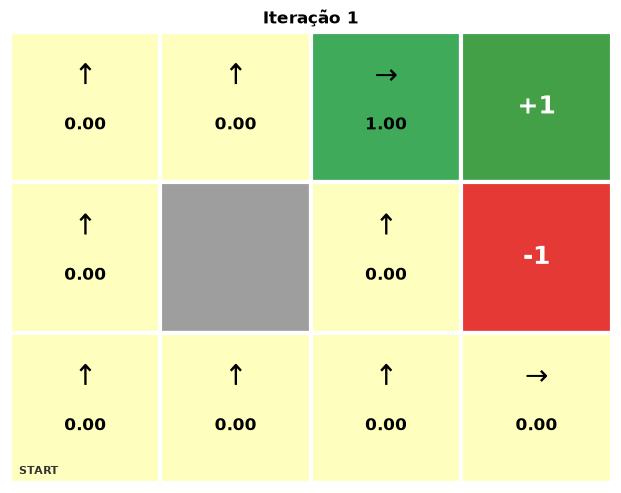

In [7]:
# Execute esta célula repetidamente — cada execução é uma varredura (γ = 0,9, determinístico)
try:
    iteracao
except NameError:
    iteracao, V = 0, {s: 0.0 for s in ESTADOS}

V, politica, delta = varredura(V)
iteracao += 1
print(f'Iteração {iteracao} | delta = {delta:.4f}')
plot_grade(V, politica, titulo=f'Iteração {iteracao}')

In [8]:
# Reseta o passo a passo
del iteracao
print('Resetado! Execute a célula acima de novo para recomeçar.')

Resetado! Execute a célula acima de novo para recomeçar.


---
## 6. Convergência completa e comparação com a aula (item 2 do slide 66)

A função `value_iteration` faz sozinha o que você fez à mão na seção 5: repete varreduras até o delta ficar menor que θ = 0,000001.

**O que conferir na saída:**

- **A tabela:** compara, casa a casa, o valor dos slides 62–64 com o calculado. Todos devem dar ✅.
- **A grade:** é a resposta do MDP. O número em cada casa é **V\***, e a seta é a **política ótima π\***.

Convergiu em 6 varreduras.

  célula   aula  calculado
  (0, 2)   1.00     1.0000 ✅
  (0, 1)   0.90     0.9000 ✅
  (0, 0)   0.81     0.8100 ✅
  (1, 0)   0.73     0.7290 ✅
  (2, 0)   0.66     0.6561 ✅
  (1, 2)   0.90     0.9000 ✅
  (2, 2)   0.81     0.8100 ✅
  (2, 1)   0.73     0.7290 ✅
  (2, 3)   0.73     0.7290 ✅


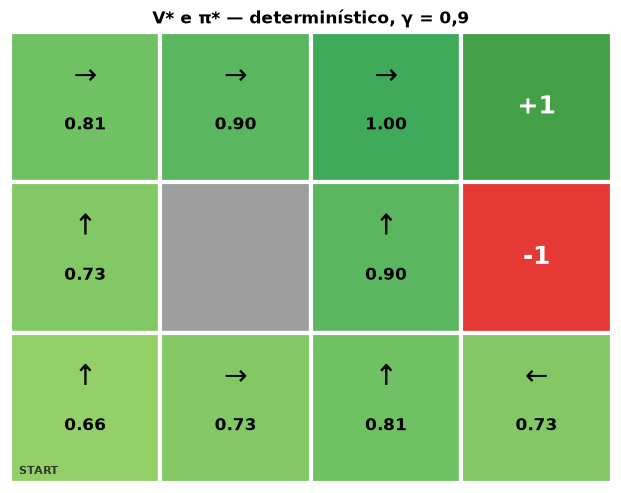

In [9]:
# ======================================================================
# 📚 NA AULA · VALUE ITERATION completo
#   Repete varreduras até nada mudar (delta < θ) → V* e π*.
# ======================================================================
def value_iteration(gamma=0.9, ruido=0.0, r_fogo=-1.0, r_passo=0.0, theta=1e-6, max_iter=10_000):
    '''Roda varreduras até delta < θ. Devolve (V*, π*, histórico de deltas).'''
    V = {s: 0.0 for s in ESTADOS}
    deltas = []
    for _ in range(max_iter):
        V, politica, delta = varredura(V, gamma, ruido, r_fogo, r_passo)
        deltas.append(delta)
        if delta < theta:
            break
    return V, politica, deltas


V_det, pi_det, deltas_det = value_iteration(gamma=0.9)
print(f'Convergiu em {len(deltas_det)} varreduras.\n')

# Os valores da aula (slides 62–64), casa a casa
aula = {(0, 2): 1.00, (0, 1): 0.90, (0, 0): 0.81, (1, 0): 0.73, (2, 0): 0.66,
        (1, 2): 0.90, (2, 2): 0.81, (2, 1): 0.73, (2, 3): 0.73}
print(f"{'célula':>8s} {'aula':>6s} {'calculado':>10s}")
for s, v in aula.items():
    ok = '✅' if abs(V_det[s] - v) < 0.005 else '❌'
    print(f'{str(s):>8s} {v:6.2f} {V_det[s]:10.4f} {ok}')

plot_grade(V_det, pi_det, titulo='V* e π* — determinístico, γ = 0,9')

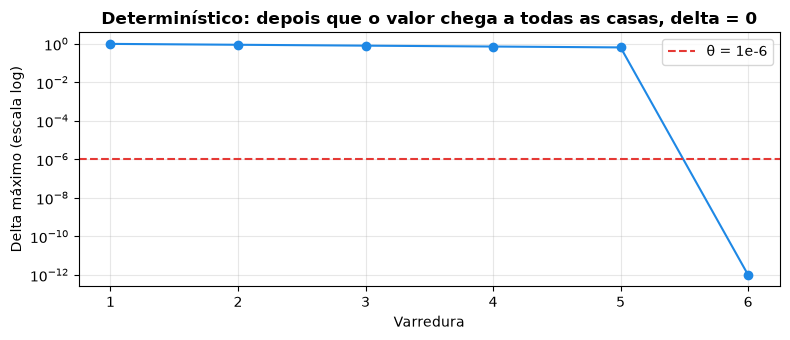

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(range(1, len(deltas_det) + 1), np.maximum(deltas_det, 1e-12), 'o-', color='#1E88E5')
ax.axhline(1e-6, color='#E53935', linestyle='--', label='θ = 1e-6')
ax.set_xlabel('Varredura')
ax.set_ylabel('Delta máximo (escala log)')
ax.set_title('Determinístico: depois que o valor chega a todas as casas, delta = 0', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

**🔎 Como ler o gráfico do delta:** o delta é a **maior mudança** de valor numa varredura.

- Ele cai a cada varredura e, na 6ª, vira **exatamente zero**, por isso o ponto some do gráfico em escala log.
- **Por que zero?** No caso determinístico, quando o valor chega a todas as casas (o START é a mais distante), não há mais nada para atualizar.
- **Na seção 9 é diferente:** com escorregões, o valor vai e volta entre as casas. O delta só vai diminuindo, e a convergência leva bem mais varreduras.

---
## 7. Saindo do START: qual caminho? (slide 64)

Seguindo sempre o vizinho de maior valor, há um **empate**. Dá para ir por cima (↑ ↑ → → →) ou por baixo (→ → ↑ ↑ →), ambos com 5 passos.

**Antes de rodar:** quanto você espera que valham ↑ e → no START? E ↓ e ←, que batem na borda?

In [11]:
# ======================================================================
# 📚 NA AULA · POLÍTICA ÓTIMA π*: em cada casa, a ação de maior valor
# ======================================================================
print('Valor de cada ação no START (determinístico, γ = 0,9):')
for a in ACOES:
    print(f'  {SETAS[a]} {a:9s} → {valor_acao(START, a, V_det):.4f}')


def seguir_politica(politica, inicio=START, max_passos=20):
    '''Caminho seguindo a política, sem ruído.'''
    s, caminho = inicio, [inicio]
    while s not in TERMINAIS and len(caminho) <= max_passos:
        s = mover(s, politica[s])
        caminho.append(s)
    return caminho


caminho = seguir_politica(pi_det)
print('\nCaminho escolhido (empate resolvido pela ordem das ações):')
print(' → '.join(map(str, caminho)), f'  [{len(caminho) - 1} passos]')

Valor de cada ação no START (determinístico, γ = 0,9):
  ↑ cima      → 0.6561
  → direita   → 0.6561
  ↓ baixo     → 0.5905
  ← esquerda  → 0.5905

Caminho escolhido (empate resolvido pela ordem das ações):
(2, 0) → (1, 0) → (0, 0) → (0, 1) → (0, 2) → (0, 3)   [5 passos]


**🔎 Como ler o resultado:**

- **↑ e → empatam em 0,6561** (= 0,9⁴). Os dois caminhos são igualmente bons.
- **↓ e ← valem 0,5905** (= 0,9 × 0,6561). Batem na borda, o agente fica parado e **perde um passo**: o mesmo valor, com um desconto a mais.
- **Quem desempata é o código:** no empate, `melhor_acao` pega a primeira ação da lista `ACOES` (↑). Por isso o caminho impresso vai por cima. Para o agente, o caminho de baixo valeria o mesmo.

---
## 8. O impacto do γ no valor do START (item 3 do slide 66)

**Antes de rodar:** o START está a 4 passos da casa que vale 1. Cada passo multiplica o valor por γ. Então V(START) = γ × γ × γ × γ = **γ⁴**.

Faça a conta antes de executar: quanto ele vale com γ = 0,5? E com γ = 0,99?

γ = 0.5    V(START) = 0.0625   (= γ⁴ = 0.0625)
γ = 0.9    V(START) = 0.6561   (= γ⁴ = 0.6561)
γ = 0.99   V(START) = 0.9606   (= γ⁴ = 0.9606)


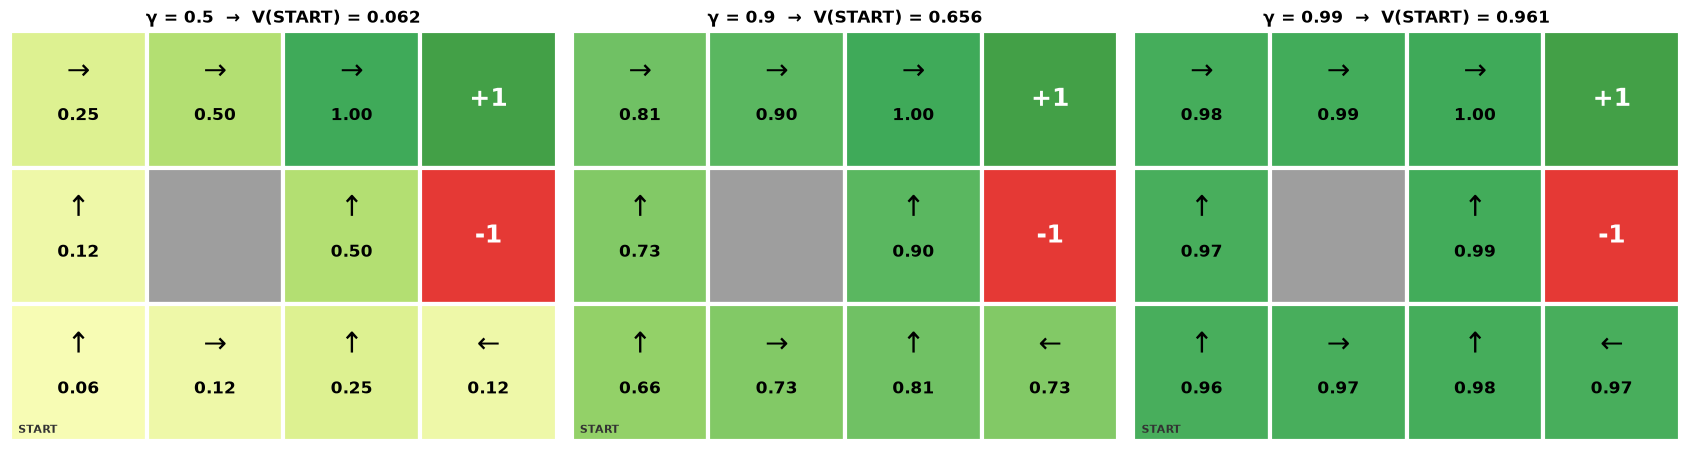


γ baixo: o prêmio distante quase não vale nada (agente imediatista).
γ alto : o prêmio distante vale quase o mesmo que o próximo (agente visionário).


In [12]:
# ======================================================================
# 📚 NA AULA · MDP: ingrediente γ (fator de desconto)
#   γ pequeno = agente imediatista; γ perto de 1 = pensa no longo prazo.
# ======================================================================
gammas = [0.5, 0.9, 0.99]
fig, axes = plt.subplots(1, len(gammas), figsize=(17, 4.5))
for ax, g in zip(axes, gammas):
    V_g, pi_g, d_g = value_iteration(gamma=g)
    plot_grade(V_g, pi_g, ax=ax, titulo=f'γ = {g}  →  V(START) = {V_g[START]:.3f}')
    print(f'γ = {g:<5}  V(START) = {V_g[START]:.4f}   (= γ⁴ = {g ** 4:.4f})')
plt.tight_layout()
plt.show()
print('\nγ baixo: o prêmio distante quase não vale nada (agente imediatista).')
print('γ alto : o prêmio distante vale quase o mesmo que o próximo (agente visionário).')

**🔎 Como ler o resultado:**

| γ | V(START) = γ⁴ | Leitura |
|---|---|---|
| 0,5 | 0,06 | O diamante, a 5 passos, quase não vale nada: **agente imediatista** |
| 0,9 | 0,66 | O valor da aula |
| 0,99 | 0,96 | O diamante distante vale quase tanto quanto o próximo: **agente visionário** |

**Repare nas setas:** são iguais nas três grades. Aqui o único prêmio positivo é o diamante, então o γ muda **quanto** cada casa vale, mas não **para onde** ir. O γ passa a mudar a política quando há escolhas entre um prêmio pequeno perto e um grande longe.

---
## 9. Movimento ruidoso: 80% / 10% / 10% (slide 50)

Agora o agente escorrega. Pergunta do slide 50: **vale passar ao lado do fogo para chegar mais rápido ao diamante?**

**Antes de rodar, aposte:**

1. Os valores vão **subir ou descer** em relação ao caso determinístico?
2. O empate do START (por cima × por baixo) continua?

Convergiu em 23 varreduras.

Valor de cada ação no START (ruído 0,2):
  ↑ cima      → 0.5452
  → direita   → 0.4504
  ↓ baixo     → 0.4847
  ← esquerda  → 0.4982


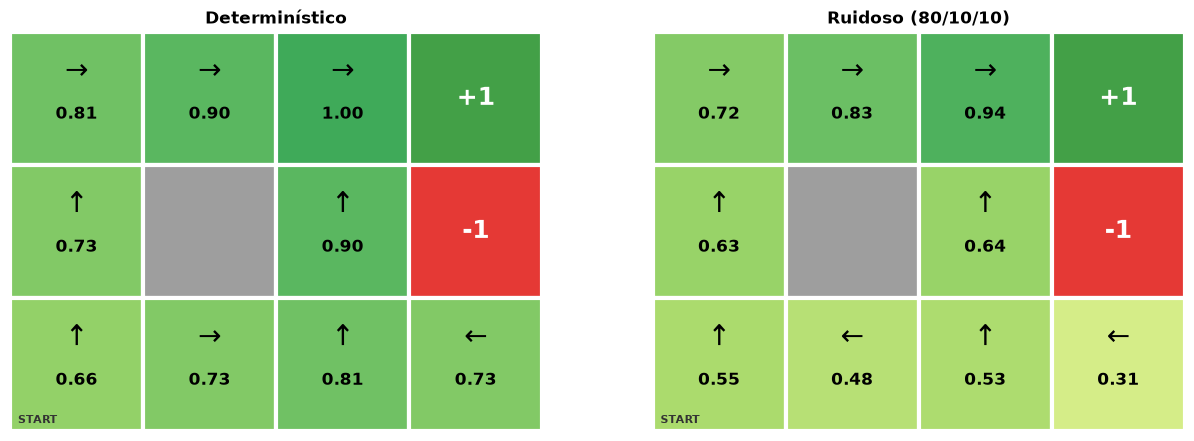

O empate do START some: ir por cima vale mais, porque o caminho de baixo passa ao lado do fogo.


In [13]:
# ======================================================================
# 📚 NA AULA · MDP: P ruidoso (o mundo escorrega)
#   A mesma Bellman, agora somando os 3 destinos possíveis de cada ação.
# ======================================================================
V_ruido, pi_ruido, d_ruido = value_iteration(gamma=0.9, ruido=0.2)
print(f'Convergiu em {len(d_ruido)} varreduras.\n')
print('Valor de cada ação no START (ruído 0,2):')
for a in ACOES:
    print(f'  {SETAS[a]} {a:9s} → {valor_acao(START, a, V_ruido, ruido=0.2):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_grade(V_det, pi_det, ax=axes[0], titulo='Determinístico')
plot_grade(V_ruido, pi_ruido, ax=axes[1], titulo='Ruidoso (80/10/10)')
plt.tight_layout()
plt.show()
print('O empate do START some: ir por cima vale mais, porque o caminho de baixo passa ao lado do fogo.')

**🔎 Como ler o resultado:**

- **Os valores caem** (o START vai de 0,66 para cerca de 0,55). Escorregar desperdiça passos e, perto do fogo, pode custar −1.
- **O empate some:** ↑ (0,545) passa a ganhar de → (0,450), porque o caminho de baixo passa colado no fogo.
- **Repare em `(2, 1)`:** a seta vira ← e manda o agente **de volta** para o START, para seguir pelo caminho de cima.
- **Repare em `(1, 2)`:** ela vale bem menos que a vizinha `(0, 2)`, embora esteja a um passo dela. A cada tentativa de subir, há 10% de chance de escorregar para o fogo.
- **Convergência:** levou 23 varreduras, contra 6 no caso determinístico.

**Resposta ao slide 50:** com escorregões, passar ao lado do fogo **não compensa**. O caminho mais seguro vale mais que o mais curto.

---
## 10. Fogo valendo −10: a política muda? (item 4 do slide 66)

Continuamos com o movimento ruidoso (80/10/10). A única mudança é o fogo, que passa a custar **−10** em vez de −1.

**Antes de rodar, aposte:** quais casas trocam de seta? Dica: olhe as vizinhas do fogo.

Casas em que a política mudou:
  (1, 2): ↑ (cima)  →  ← (esquerda)
  (2, 2): ↑ (cima)  →  ← (esquerda)
  (2, 3): ← (esquerda)  →  ↓ (baixo)


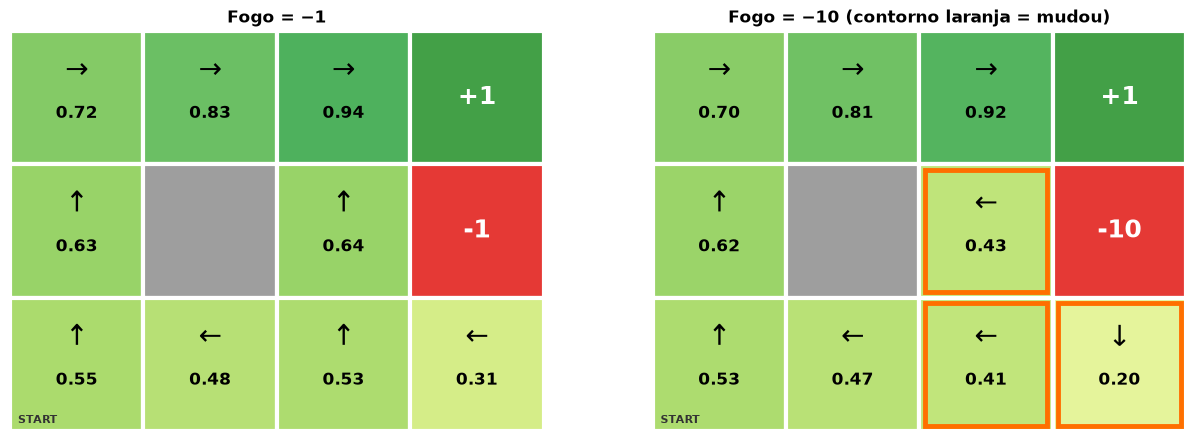


Com o fogo mais caro, o agente prefere se afastar dele — mesmo que o caminho fique mais longo
ou que ele tenha de bater na parede de propósito para não escorregar para o fogo.


In [14]:
# ======================================================================
# 📚 NA AULA · MDP: mudar R muda a política
#   O fogo mais caro faz o agente fugir dele.
# ======================================================================
V_fogo10, pi_fogo10, _ = value_iteration(gamma=0.9, ruido=0.2, r_fogo=-10)

mudaram = [s for s in pi_ruido if pi_ruido[s] != pi_fogo10[s]]
print('Casas em que a política mudou:')
for s in mudaram:
    print(f'  {s}: {SETAS[pi_ruido[s]]} ({pi_ruido[s]})  →  {SETAS[pi_fogo10[s]]} ({pi_fogo10[s]})')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_grade(V_ruido, pi_ruido, ax=axes[0], titulo='Fogo = −1')
plot_grade(V_fogo10, pi_fogo10, ax=axes[1], r_fogo=-10, destaque=mudaram,
           titulo='Fogo = −10 (contorno laranja = mudou)')
plt.tight_layout()
plt.show()
print('\nCom o fogo mais caro, o agente prefere se afastar dele — mesmo que o caminho fique mais longo')
print('ou que ele tenha de bater na parede de propósito para não escorregar para o fogo.')

**🔎 Como ler o resultado:** mudaram as três casas que têm o fogo por perto (contorno laranja).

| Casa | Fogo = −1 | Fogo = −10 | O que o agente está pensando |
|---|---|---|---|
| `(1, 2)` | ↑ | ← | Bate na parede de propósito: 80% fica parado, 10% sobe para `(0, 2)`, 10% desce. **Nunca escorrega para o fogo.** |
| `(2, 2)` | ↑ | ← | Subir passaria por `(1, 2)`, ao lado do fogo. Melhor dar a volta pela esquerda. |
| `(2, 3)` | ← | ↓ | Bate na borda de baixo: fica parado ou escorrega para os lados, e **nunca sobe para o fogo**. |

**A lição:** **as setas mudam sem que o mapa mude**. Basta alterar a recompensa. Por isso, desenhar a recompensa é uma das decisões mais importantes em RL.

---
## 11. Living penalty: o custo de cada passo (slides 68 e 69)

**A ideia:** uma pequena recompensa negativa a cada passo, como um táxi com o taxímetro ligado. Ela entra no $R(s,a)$ de **todo** passo que não termina o episódio. Quanto mais caro o passo, mais pressa o agente tem.

Para reproduzir a figura do slide 69 usamos **γ = 1** e ruído 0,2 (a configuração clássica de Russell & Norvig). Com γ = 1 não há desconto, então é a living penalty sozinha que cria a pressa.

**Antes de rodar, aposte:** com o passo custando −2, o que você faria nas casas vizinhas do fogo?

A célula gera **4 grades lado a lado**, uma para cada custo de passo. Compare as setas com o slide.

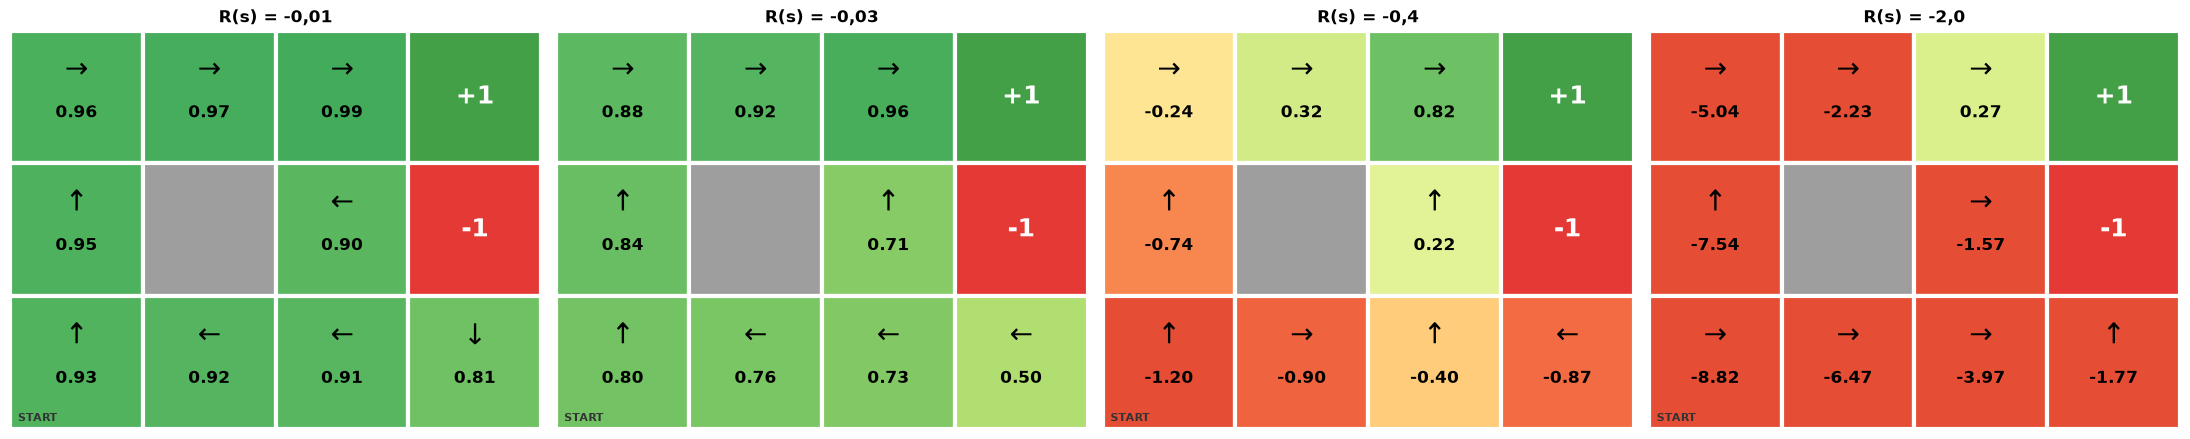

R = −0,01: passo barato → cauteloso; evita o fogo mesmo com caminho longo.
R = −0,4 : passo caro   → vai pelo caminho curto, aceitando passar perto do fogo.
R = −2,0 : viver custa mais que perder → se joga no fogo se for mais rápido.


In [15]:
# ======================================================================
# 📚 NA AULA · MDP: living penalty (R em cada passo)
#   O custo de cada passo muda a pressa (e a coragem) do agente.
# ======================================================================
penalidades = [-0.01, -0.03, -0.4, -2.0]
fig, axes = plt.subplots(1, len(penalidades), figsize=(22, 4.5))
for ax, rp in zip(axes, penalidades):
    V_p, pi_p, _ = value_iteration(gamma=1.0, ruido=0.2, r_passo=rp)
    plot_grade(V_p, pi_p, ax=ax, titulo=f'R(s) = {rp}'.replace('.', ','))
plt.tight_layout()
plt.show()

print('R = −0,01: passo barato → cauteloso; evita o fogo mesmo com caminho longo.')
print('R = −0,4 : passo caro   → vai pelo caminho curto, aceitando passar perto do fogo.')
print('R = −2,0 : viver custa mais que perder → se joga no fogo se for mais rápido.')

**🔎 Como ler as 4 grades** (da esquerda para a direita, o passo fica cada vez mais caro):

| Custo do passo | Comportamento | Onde ver na grade |
|---|---|---|
| **−0,01** (barato) | **Muito cauteloso.** Prefere demorar a arriscar o fogo. | `(1, 2)` bate na parede (←) e `(2, 3)` bate na borda (↓) para não escorregar no fogo |
| **−0,03** | **Cauteloso.** Ainda evita o caminho de baixo. | A linha de baixo toda aponta ← (volta pelo caminho de cima) |
| **−0,4** (caro) | **Apressado.** Aceita passar perto do fogo para chegar logo. | A linha de baixo vai → e ↑: caminho curto |
| **−2,0** (caríssimo) | **Desesperado.** Viver custa mais que o fogo (−1). | `(1, 2)` e `(2, 3)` apontam **para dentro do fogo**: acabar logo dói menos que continuar |

**A lição:** a living penalty é um "botão" de pressa. Ela é útil para evitar um agente que fica enrolando, mas, se for exagerada, ensina o agente a desistir.

---
## 12. Resumo

| Conceito | Neste notebook | Onde vimos |
|---|---|---|
| **Estado (s)** | Casa (linha, coluna) da grade | Seção 2 |
| **Ação (a)** | ↑ ↓ ← → | Seção 2 |
| **Transição P(s'\|s,a)** | Determinística ou ruidosa 80/10/10 | Seções 3 e 9 |
| **Recompensa R** | +1 diamante, −1 fogo (ou −10), 0 ou living penalty por passo | Seções 4, 10 e 11 |
| **γ** | 0,9 — cada casa a mais multiplica o valor por 0,9 | Seção 8 |
| **V(s)** | O número em cada casa: 1 → 0,9 → 0,81 → 0,73 → 0,66 | Seções 5 e 6 |
| **Política π\*** | A seta em cada casa: a ação de maior valor | Seções 6, 7 e 9–11 |

**Três lições para levar:**

1. **O valor nasce no objetivo e se espalha para trás**, perdendo um pouco (γ) a cada passo.
2. **A política depende de tudo:** mude o ruído, o castigo do fogo ou o custo do passo, e as setas mudam — o mapa continua o mesmo.
3. **Risco entra na conta sozinho:** com escorregões, a equação de Bellman já pondera "e se eu cair no fogo?". Ninguém precisa programar "fique longe do fogo".

**Em uma frase (slide 65):** RL não é ganhar hoje, é escolher o caminho que rende mais na jornada inteira.

**Próximo passo:** aqui o agente **conhece P e R** (model-based) e consegue planejar sem dar nenhum passo. No mundo real ele quase nunca conhece o modelo e precisa aprender jogando — é o que veremos com **Monte Carlo, Diferença Temporal e Q-Learning**.